In [1]:
import pickle
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from models.EEGNet import EEGNet, ConstrainedConv2d, ConstrainedLinear
from models.GATGRU import MultiBranchGATGRUTransformer, SpatialBranch, FrequencyBranch, TemporalBranch, GATLayer

RESULTS_DIR = pathlib.Path('data/results')

def load_cached(name: str):
    cache_path = RESULTS_DIR / f"{name}.pkl"

    with open(cache_path, "rb") as fh:
        cached = pickle.load(fh)
        return cached["result"]

# rf_general_run = load_cached('rf_general_run')
# rf_leave_one_out_run = load_cached('rf_leave_one_out_run')
# rf_leave_one_out_gaze_run = load_cached('rf_leave_one_out_gaze_run')
# rf_leave_one_out_hinted_run = load_cached('rf_leave_one_out_hinted_run')
# rf_leave_one_out_ignored_run = load_cached('rf_leave_one_out_ignored_run')
# rf_cross_session_run = load_cached('rf_cross_session_run')
rf_general_run, rf_general_run_meta = load_cached('eegnet_general_run')
rf_leave_one_out_run = load_cached('eegnet_leave_one_out_run')
rf_leave_one_out_gaze_run = load_cached('eegnet_leave_one_out_gaze_run')
rf_leave_one_out_hinted_run = load_cached('eegnet_leave_one_out_hinted_run')
rf_leave_one_out_ignored_run = load_cached('eegnet_leave_one_out_ignored_run')
rf_cross_session_run, rf_cross_session_run_meta = load_cached('eegnet_cross_session_run')

eegnet_general_run, eegnet_general_run_meta = load_cached('eegnet_general_run')
eegnet_leave_one_out_run = load_cached('eegnet_leave_one_out_run')
eegnet_leave_one_out_gaze_run = load_cached('eegnet_leave_one_out_gaze_run')
eegnet_leave_one_out_hinted_run = load_cached('eegnet_leave_one_out_hinted_run')
eegnet_leave_one_out_ignored_run = load_cached('eegnet_leave_one_out_ignored_run')
eegnet_cross_session_run, eegnet_cross_session_run_meta = load_cached('eegnet_cross_session_run')

transformer_general_run = load_cached('transformer_general_run')
transformer_cross_session_run, transformer_cross_session_run_meta = load_cached('transformer_cross_session_run')
transformer_leave_one_out_run = load_cached('transformer_leave_one_out_run')
transformer_leave_one_out_gaze_run = load_cached('transformer_leave_one_out_gaze_run')
transformer_leave_one_out_hinted_run = load_cached('transformer_leave_one_out_hinted_run')
transformer_leave_one_out_ignored_run = load_cached('transformer_leave_one_out_ignored_run')

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\nicol\_netrc.
wandb: Currently logged in as: nbaeriswyl (nbaeriswyl-eth-z-rich) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


# Results analysis

In [2]:
rf_cross_session_run

{'model': EEGNet(
   (block1): Sequential(
     (0): Conv2d(1, 8, kernel_size=(1, 150), stride=(1, 1), padding=same, bias=False)
     (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
     (2): ConstrainedConv2d(8, 16, kernel_size=(20, 1), stride=(1, 1), groups=8, bias=False)
     (3): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
     (4): ELU(alpha=1.0)
     (5): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
     (6): Dropout(p=0.25, inplace=False)
   )
   (block2): Sequential(
     (0): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), padding=same, groups=16, bias=False)
     (1): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
     (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
     (3): ELU(alpha=1.0)
     (4): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
     (5): Dropout(p=0.25, inplace=False)
   )
   (cla

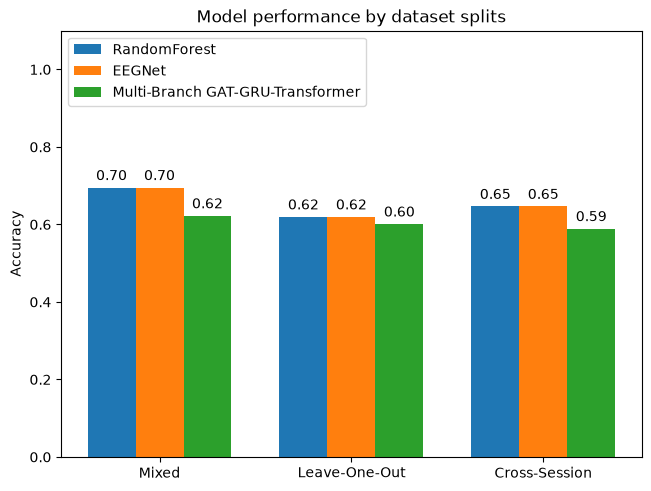

In [3]:
# model comparison - overall
def plot_overall_performance_comparison():
    dataset_names = ['Mixed', 'Leave-One-Out', 'Cross-Session']
    content = {
        'RandomForest': (rf_general_run['test_accuracy'],
                         np.average([v['result']['test_accuracy'] for k, v in rf_leave_one_out_run.items()]),
                         rf_cross_session_run['test_accuracy']),
        'EEGNet': (eegnet_general_run['test_accuracy'],
                   np.average([v['result']['test_accuracy'] for k, v in eegnet_leave_one_out_run.items()]),
                   eegnet_cross_session_run['test_accuracy']),
        'Multi-Branch GAT-GRU-Transformer': (
            transformer_general_run['test_accuracy'],
            np.average([v['result']['test_accuracy'] for k, v in transformer_leave_one_out_run.items()]),
            transformer_cross_session_run['test_accuracy'],
        )
    }

    fig, ax = plt.subplots(layout='constrained')

    res = ax.grouped_bar(content, tick_labels=dataset_names, group_spacing=1)
    for container in res.bar_containers:
        ax.bar_label(container, padding=3, fmt="%.2f")

    # Add some text for labels, title, etc.
    ax.set_ylabel('Accuracy')
    ax.set_title('Model performance by dataset splits')
    ax.legend(loc='upper left', ncols=1)
    ax.set_ylim(0, 1.1)

plot_overall_performance_comparison()

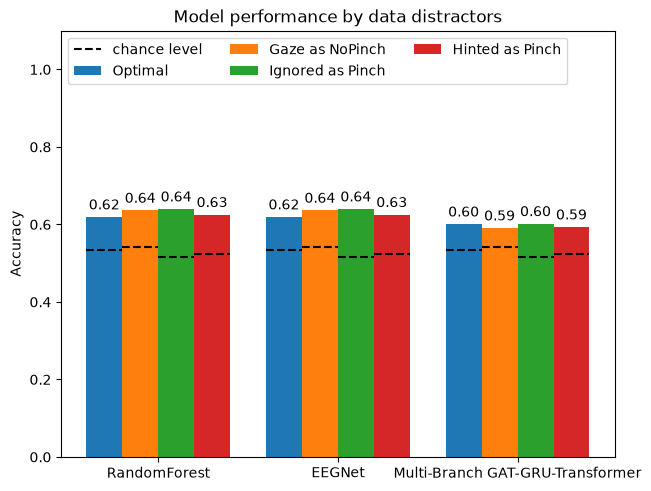

In [4]:
# model comparison - impact of hinted, ignored, and gaze events in leave-one-out

def get_accs_by_type(type: str):
    return (
        get_acc(globals()[f'rf_{type}']),
        get_acc(globals()[f'eegnet_{type}']),
        get_acc(globals()[f'transformer_{type}'])
    )

def get_baseline_by_type(type: str):
    return (
        get_baseline(globals()[f'rf_{type}']),
        get_baseline(globals()[f'eegnet_{type}']),
        get_baseline(globals()[f'transformer_{type}'])
    )

def get_acc(data: dict):
    if 'result' in data:
        return data['result']['test_accuracy']
    else:
        return np.average([v['result']['test_accuracy'] for k, v in data.items()])

def get_baseline(data: dict):
    """
    Estimate the baseline accuracy using the majority-class baseline.
    """
    if 'result' in data:
        cm = np.asarray(data['result']["confusion_matrix"])
        true_class_counts = cm.sum(axis=1)  # rows = true labels
        total = true_class_counts.sum()
        return true_class_counts.max() / total
    else:
        true_class_counts = 0
        total = 0
        for s in data.keys():
            cm = np.asarray(data[s]['result']["confusion_matrix"])
            true_class_counts += cm.sum(axis=1).max()  # rows = true labels
            total += cm.sum(axis=1).sum()

        return true_class_counts / total


def plot_overall_performance_comparison():
    dataset_names = ['RandomForest', 'EEGNet', 'Multi-Branch GAT-GRU-Transformer']
    content = {
        'Optimal': get_accs_by_type('leave_one_out_run'),
        'Gaze as NoPinch': get_accs_by_type('leave_one_out_gaze_run'),
        'Ignored as Pinch': get_accs_by_type('leave_one_out_ignored_run'),
        'Hinted as Pinch': get_accs_by_type('leave_one_out_hinted_run'),
        # 'Random finger movements\nas NoPinch': get_accs_by_type('leave_one_out_run'),
    }
    chance = {
        'Optimal': get_baseline_by_type('leave_one_out_run'),
        'Gaze as NoPinch': get_baseline_by_type('leave_one_out_gaze_run'),
        'Ignored as Pinch': get_baseline_by_type('leave_one_out_ignored_run'),
        'Hinted as Pinch': get_baseline_by_type('leave_one_out_hinted_run'),
        # 'Random finger movements\nas NoPinch': (0.5, 0.5, 0.5),
    }

    fig, ax = plt.subplots(layout='constrained')

    res = ax.grouped_bar(content, tick_labels=dataset_names, group_spacing=1)

    # plot a per-bar chance level (determined by the ratio of the dominant class)
    first_line = True
    for label, container in zip(content, res.bar_containers):
        for bar, c in zip(container.patches, chance[label]):
            ax.hlines(c, bar.get_x(), bar.get_x() + bar.get_width(),
                      colors='black', linestyles='--', linewidth=1.5,
                      label='chance level' if first_line else None)
            first_line = False

    for container in res.bar_containers:
        ax.bar_label(container, padding=3, fmt="%.2f")

    ax.set_ylabel('Accuracy')
    ax.set_title('Model performance by data distractors')
    ax.legend(loc='upper left', ncols=3)
    ax.set_ylim(0, 1.1)

plot_overall_performance_comparison()

In [5]:
# model comparison - impact of feedback